# Datos Faltantes

In [2]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [4]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
157,-0.001882,0.050680,-0.033151,-0.018306,0.031454,0.042840,-0.013948,0.019917,0.010227,0.027917,84.0
113,0.019913,0.050680,0.014272,0.063187,0.014942,0.020293,-0.047082,0.034309,0.046662,0.090049,297.0
249,-0.012780,-0.044642,0.060618,0.052858,0.047965,0.029375,-0.017629,0.034309,0.070207,0.007207,215.0
171,-0.020045,-0.044642,-0.046085,-0.098627,-0.075870,-0.059873,-0.017629,-0.039493,-0.051404,-0.046641,74.0
422,-0.078165,0.050680,0.077863,0.052858,0.078236,0.064447,0.026550,-0.002592,0.040673,-0.009362,233.0
285,0.012648,-0.044642,-0.020218,-0.015999,0.012191,0.021233,-0.076536,0.108111,0.059879,-0.021788,233.0
365,0.034443,-0.044642,-0.038540,-0.012556,0.009439,0.005262,-0.006584,-0.002592,0.031193,0.098333,206.0
156,-0.016412,-0.044642,-0.010517,0.001215,-0.037344,-0.035760,0.011824,-0.039493,-0.021395,-0.034215,25.0
195,0.027178,0.050680,0.025051,0.014987,0.025950,0.048477,-0.039719,0.034309,0.007838,0.023775,122.0
366,-0.045472,0.050680,0.137143,-0.015999,0.041086,0.031880,-0.043401,0.071210,0.071019,0.048628,233.0


In [5]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [6]:
data.isnull().sum()

age        0
sex        0
bmi       44
bp        44
s1         0
s2         0
s3         0
s4         0
s5         0
s6         0
target     0
dtype: int64

### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [9]:
imputer = SimpleImputer(strategy="mean")

data[["bmi"]] = imputer.fit_transform(data[["bmi"]])

data["bmi"].isnull().sum()

np.int64(0)

### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [10]:
# Copias del dataset para comparar métodos
data_simple = data.copy()
data_knn = data.copy()

# 1. Imputación simple con media
simple_imputer = SimpleImputer(strategy="mean")

data_simple[["bmi", "bp"]] = simple_imputer.fit_transform(
    data_simple[["bmi", "bp"]]
)

# 2. Imputación con KNN
knn_imputer = KNNImputer(n_neighbors=5)

data_knn[["bmi", "bp"]] = knn_imputer.fit_transform(
    data_knn[["bmi", "bp"]]
)

# Comprobar que ya no haya valores faltantes
print("Faltantes con imputación simple:")
print(data_simple[["bmi", "bp"]].isnull().sum())

print("\nFaltantes con KNN:")
print(data_knn[["bmi", "bp"]].isnull().sum())

comparacion = pd.DataFrame({
    "bmi_simple": data_simple["bmi"],
    "bmi_knn": data_knn["bmi"],
    "bp_simple": data_simple["bp"],
    "bp_knn": data_knn["bp"]
})

comparacion.head(20)

Faltantes con imputación simple:
bmi    0
bp     0
dtype: int64

Faltantes con KNN:
bmi    0
bp     0
dtype: int64


,bmi_simple,bmi_knn,bp_simple,bp_knn
0,0.061696,0.061696,0.021872,0.021872
1,-0.051474,-0.051474,0.000465,0.003970
2,0.044451,0.044451,-0.005670,-0.005670
3,-0.011595,-0.011595,-0.036656,-0.036656
4,-0.036385,-0.036385,0.021872,0.021872
5,-0.040696,-0.040696,-0.019442,-0.019442
6,-0.047163,-0.047163,-0.015999,-0.015999
7,-0.001895,-0.001895,0.066629,0.066629
8,0.061696,0.061696,-0.040099,-0.040099
9,-0.000205,-0.000205,-0.033213,-0.033213


### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

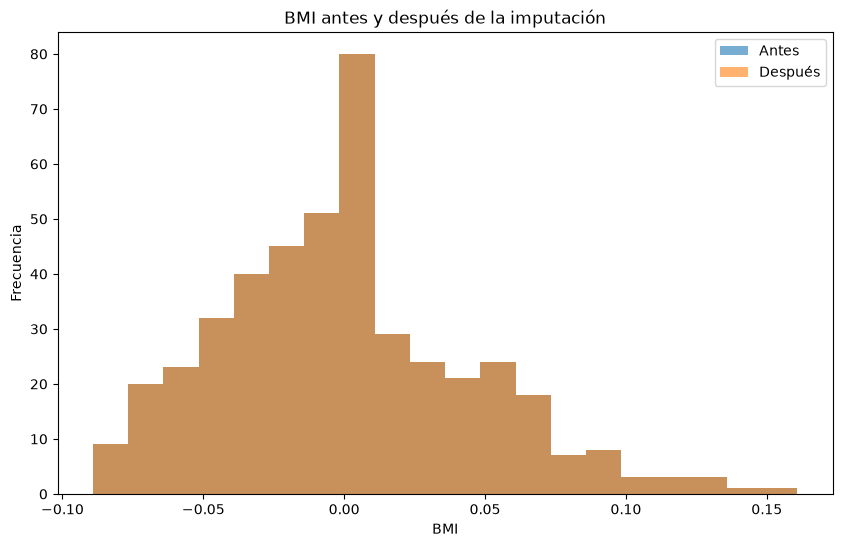

In [16]:
data_original = data.copy()

imputer = SimpleImputer(strategy="mean")
data[["bmi"]] = imputer.fit_transform(data[["bmi"]])

plt.figure(figsize=(10, 6))

plt.hist(data_original["bmi"].dropna(), bins=20, alpha=0.6, label="Antes")
plt.hist(data["bmi"], bins=20, alpha=0.6, label="Después")

plt.xlabel("BMI")
plt.ylabel("Frecuencia")
plt.title("BMI antes y después de la imputación")
plt.legend()

plt.show()

# La imputación por media conserva en gran medida la distribución general de bmi, aunque aumenta artificialmente la frecuencia alrededor del valor medio.